## Question 1.1
####

In [50]:
#importing libraries 
import re
import warnings
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
import pandas as pd

warnings.filterwarnings('ignore')

#download nltk resources for preprocessing
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

#loading dataframe
df = pd.read_json('research_abstracts.json')

print(df.shape)

(1138, 3)


In [51]:
#adding stopwords and intialising lemmetizer
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

In [52]:
#clean and denoise the abstract
def preprocess_text(text):
    text = str(text)
    clean_text = re.sub(r'[^a-zA-Z\s]','',text)
    clean_text = clean_text.lower()
    word_tokens = word_tokenize(clean_text)

    filtered_words = [
        lemmatizer.lemmatize(w)
        for w in word_tokens
        if w not in stop_words and len(w) > 1
    ]
    return ' '.join(filtered_words)

#apply cleaning to Abstract column
df['clean_text'] = df['Abstract'].apply(preprocess_text)
df[['Abstract', 'clean_text', 'Label']].head()
        

,Abstract,clean_text,Label
0,Forward-looking forecasting of the inflation r...,forwardlooking forecasting inflation rate coul...,ai
1,Our study examined the disaggregation of infla...,study examined disaggregation inflation compon...,ai
2,This paper develops a dynamic factor model tha...,paper develops dynamic factor model us euro ar...,classical
3,"In this paper, I use a simple SIR Macro model ...",paper use simple sir macro model examine japan...,classical
4,BackgroundGame theory is useful for identifyin...,backgroundgame theory useful identifying condi...,classical


## Question 1.2


### Feature engineering usinf feature techniques


In [53]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer

#generating TF-IDF feature matrix 
tfidf_vec = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_tfidf = tfidf_vec.fit_transform(df['clean_text'])
print('TF-IDF shae', X_tfidf.shape)

#convert research categories into smaller labels for classification
labels = np.array([1 if label == 'ai' else 0 for label in df['Label']])
texts = df['clean_text'].values

# tokenise and pad sequences for the neural network
max_features = 10000
maxlen = 250

tokenizer  = Tokenizer(num_words=max_features)
tokenizer.fit_on_texts(texts)
sequences = tokenizer.texts_to_sequences(texts)

X_seq = pad_sequences(sequences, maxlen=maxlen)
print('Sequence data shape', X_seq.shape)

TF-IDF shae (1138, 5000)
Sequence data shape (1138, 250)


## Quesion 1.3

### Build baseline model and provide performance report for model learning and generalization

In [54]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import Dense, Embedding, LSTM
from tensorflow.keras.models import Sequential

# splitting the train test sets
X_train, X_test, y_train, y_test = train_test_split(
    X_seq, labels, test_size=0.20, random_state=42, stratify=labels
)

# build the LSTM baseline model
model = Sequential()
model.add(Embedding(max_features, 32, input_length=maxlen))
model.add(LSTM(64, dropout=0.2, recurrent_dropout=0.2))
model.add(Dense(1, activation='sigmoid'))

model.compile(optimizer='rmsprop', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)              │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_6 (LSTM)                        │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [55]:
#train the LSTM modeland track training and validation performane
history = model.fit(
    X_train, y_train, epochs=10, batch_size=32, validation_split=0.2
)

# plot training and validation accuracy and loss
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs = range(1, len(acc) + 1)


Epoch 1/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 15s 289ms/step - accuracy: 0.7843 - loss: 0.5626 - val_accuracy: 0.7857 - val_loss: 0.5279
Epoch 2/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 6s 242ms/step - accuracy: 0.7926 - loss: 0.5072 - val_accuracy: 0.7857 - val_loss: 0.5120
Epoch 3/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 6s 241ms/step - accuracy: 0.7926 - loss: 0.5026 - val_accuracy: 0.7857 - val_loss: 0.4915
Epoch 4/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 6s 237ms/step - accuracy: 0.8242 - loss: 0.4306 - val_accuracy: 0.8462 - val_loss: 0.3934
Epoch 5/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 6s 239ms/step - accuracy: 0.8942 - loss: 0.3171 - val_accuracy: 0.8462 - val_loss: 0.3752
Epoch 6/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 10s 240ms/step - accuracy: 0.9286 - loss: 0.2311 - val_accuracy: 0.8626 - val_loss: 0.3615
Epoch 7/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 6s 243ms/step - accuracy: 0.9505 - loss: 0.1748 - val_accuracy: 0.8516 - val_loss: 0.3743
Epoch 8/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 6s 238ms/step - accuracy: 0.9698 - loss: 0.1191 - val_accuracy: 

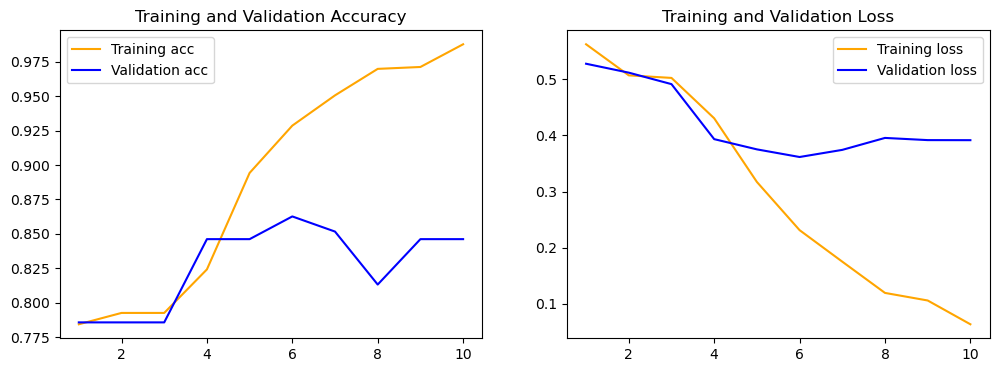

8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 161ms/step
              precision    recall  f1-score   support

   classical       0.93      0.94      0.94       180
          ai       0.78      0.73      0.75        48

    accuracy                           0.90       228
   macro avg       0.85      0.84      0.84       228
weighted avg       0.90      0.90      0.90       228

[[170  10]
 [ 13  35]]


In [56]:
# plot the training set and validation accuracy and loss

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, acc, 'orange', label='Training acc')
plt.plot(epochs, val_acc, 'blue', label='Validation acc')
plt.title('Training and Validation Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, loss, 'orange', label='Training loss')
plt.plot(epochs, val_loss, 'blue', label='Validation loss')
plt.title('Training and Validation Loss')
plt.legend()

plt.show()

#predict the test labels and evaluate the model
y_pred_prod = model.predict(X_test)
y_pred_classes = (y_pred_prod > 0.5).astype(int).flatten()

print(
    classification_report(
        y_test, y_pred_classes, target_names=['classical','ai']
    )
)
print(confusion_matrix(y_test, y_pred_classes))

#### Performance model
The LSTM model achieved 89% accuracy whole training accuracy up to 98% and the training loss dropped to 0.07 on the
10 epochs.Epoch 3-4 had a mild overfitting due to small dataset size. 

## Question 2.1
#### Enhance predictive performance

In [199]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

# splitting the train test sets
X_train_tf, X_test_tf, y_train_tf, y_test_tf= train_test_split(
    X_tfidf, labels, test_size=0.20, random_state=42, stratify=labels
)

#define the classification models to compare
models = {
    'Multinomial Naive Bayes': MultinomialNB(),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Linear SVM': LinearSVC(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42)
}

results = []

#train and evaluate each model using accuracy and macro F1 score
for name, clf in models.items():
    clf.fit(X_train_tf, y_train_tf)
    preds = clf.predict(X_test_tf)
    acc = accuracy_score(y_test_tf, preds)
    macro_f1 = f1_score(y_test_tf, preds, average='macro')
    results.append({'Model': name, 'Accuracy': acc, 'Macro F1': macro_f1})
    
results_df = pd.DataFrame(results)
display(results_df)

#displat the classification report for the last model
print(classification_report(y_test_tf, preds, target_names=['classical','ai']))


,Model,Accuracy,Macro F1
0,Multinomial Naive Bayes,0.864035,0.721897
1,Logistic Regression,0.864035,0.721897
2,Linear SVM,0.921053,0.868664
3,Random Forest,0.912281,0.845340


              precision    recall  f1-score   support

   classical       0.90      0.99      0.95       180
          ai       0.97      0.60      0.74        48

    accuracy                           0.91       228
   macro avg       0.94      0.80      0.85       228
weighted avg       0.92      0.91      0.90       228



In [200]:
print(df['clean_text'].head(3).tolist())

['forwardlooking forecasting inflation rate could help central bank government department better use monetary policy stabilize price prevent impact inflation market entity especially low middleincome group also help financial institution investor better make investment decision sense forecast inflation rate great significance existing literature mainly us linear model autoregressive ar vector autoregressive var model predict inflation rate nonlinear relationship variable mining historical data information relatively lacking therefore prediction strategy accuracy existing literature need improved predictive model designed deep learning fully mine nonlinear relationship variable process complex longterm time series dynamic information thereby making deficiency existing research therefore paper employ recurrent neural network gated recurrent unit grurnn model train analyze consumer price index cpi indicator obtain inflationrelated prediction result experimental result historical data show

The four models were trained and evaluated to improve the baseline models predictice perofrmance. Linear SVM achieved the highest accuracy of 92,11% amd macro F1-score of 0.87, followed by RandomForest with 91.23%, Multinomial Naive Bayes and LOgistics Regression both achieved 86.40% accuracy. The results show that Linear SVM performed best out of the four models.

## Question 2.2
#### Additional enhancement approach predictive performance model

In [202]:
import joblib
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

#split raw cleaned text sp TFIDF fits strictly inside folds
X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    df['clean_text'], labels, test_size=0.20, random_state=42, stratify=labels
)

# create pipeline combining TF-IDF nad Linear SVM
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)),
    ('clf', LinearSVC(class_weight='balanced', random_state=42))
])

#define the params to test during the hyperparameter tuning
param_grid = {
     'tfidf__max_features':[3000, 5000, 10000],
     'clf__C': [0.1, 0.5, 1.0, 2.0]
}

#train the model and evaluate the best config
grid_search = GridSearchCV(
    pipeline, param_grid, cv=5, scoring='f1_macro', n_jobs=-1
)

grid_search.fit(X_train_raw, y_train_raw)

best_model = grid_search.best_estimator_
y_pred_enhanced = best_model.predict(X_test_raw)


print(grid_search.best_params_)
print(round(accuracy_score(y_test_raw, y_pred_enhanced), 4),
     )
print(
    classification_report(
        y_test_raw, 
        y_pred_enhanced, 
        target_names=['classical','ai']
    )
)


{'clf__C': 0.5, 'tfidf__max_features': 5000}
0.9254
              precision    recall  f1-score   support

   classical       0.95      0.96      0.95       180
          ai       0.84      0.79      0.82        48

    accuracy                           0.93       228
   macro avg       0.89      0.88      0.89       228
weighted avg       0.92      0.93      0.92       228



## Question 2.3

#### Deploying algorithmic configuration from web-interface for testing

In [203]:
joblib.dump(best_model, 'researchly_classifier.pkl')
print('Saved Researchly_classifier.pkl')

Saved Researchly_classifier.pkl


In [204]:
%%writefile app.py
import re
import joblib
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
import streamlit as st

st.title('Researchly Abstract Classifier')
st.write('This app classifies research abstract as either AI related or classical research')

#nltk.download('punkt', quiet=True)
#nltk.download('punkt_tab', quiet=True)
#nltk.download('stopwords', quiet=True)
#nltk.download('wordnet', quiet=True)

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()
model = joblib.load('researchly_classifier.pkl')

def preprocess_text(text):
    clean_text = re.sub(r'[^a-zA-Z\s]','',str(text)).lower()
    tokens = word_tokenize(clean_text)

    filtered_words = [
        lemmatizer.lemmatize(w)
        for w in tokens
        if w not in stop_words and len(w) > 1
    ]
    return ' '.join(filtered_words)

abstract_input = st.text_area('Enter research abstract', height=200)

if st.button('Classify Abstract'):
    if abstract_input.strip():
        cleaned = preprocess_text(abstract_input)
        prediction = model.predict([cleaned])
        
        st.subheader('Prediction')
        if prediction[0] == 1:
             st.success('The abstract is classifies as: artificial research')
        else:
            st.success('The abstract is classifies as: classical research')
    else:
        st.warning('Please eneter research abstract before classifying')
            
                 

Overwriting app.py


The LinearSVC model was selected for deployment because of strong classification performance, with an accuracy of appriximately
92.54% and macro F1-score of 0.89. The model improved performance of the artifical research class compared with the baseline LSTM. It is the suitable
choice for research abstract classification application.

## Question 3.1
#### Generate dataframe of all research articles

In [123]:
!pip install pypdf wordcloud -q

In [134]:
import pandas as pd
import os 
import zipfile
from pypdf import PdfReader

#extract the research_corpus zip folder
extract_dir = 'research_corpus_files'
with zipfile.ZipFile('research_corpus.zip', 'r') as zip_ref:
    zip_ref.extractall(extra)

articles_data = []

# browse the folder and read the files

for root, dirs, files in os.walk(extract_dir):
    for file in sorted(files):
        if file.startswith('.') or '__MACOSX' in root:
            continue

        file_path = os.path.join(root, file)
        content = ''
            
        if file.lower().endswith('.txt'):
             with open(file_path, 'r', encoding='utf-8', errors='ignore') as f:
               content = f.read()
                    
        if content.strip():
          articles_data.append({'Articles_Title': file, 'Content': content})

# create dataframe of research articles
articles_df = pd.DataFrame(articles_data)
print('Total articles loaded:', len(articles_df))
articles_df.head()

Total articles loaded: 5


,Articles_Title,Content
0,research_1.txt,The purposes of this article are to position m...
1,research_2.txt,"Now I see it, now I don’t:\nresearcher’s posit..."
2,research_3.txt,DEVELOPMENTAL RESEARCH: STUDIES OF\nINSTRUCTIO...
3,research_4.txt,Abstract\nCronbach’s alpha is a statistic comm...
4,research_5.txt,Denzin’s Paradigm Shift: Revisiting Triangulat...


## Question 3.2
#### Preprocess each research article content using state-of-the-art denoising techniques

In [205]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def denoise_article(text):
    clean_text = re.sub(r'http\S+|www\S+', '', str(text))
    clean_text = re.sub(r'[^a-zA-Z\s]', ' ',clean_text)
    clean_text = clean_text.lower()

    tokens = word_tokenize(clean_text)
    cleaned_tokens = [
        lemmatizer.lemmatize(w)
        for w in tokens
        if w not in stop_words and len(w) > 2
    ]
    return ' '.join(cleaned_tokens)

articles_df['Clean_Content'] = articles_df['Content'].apply(denoise_article)
articles_df[['Articles_Title','Content', 'Clean_Content']].head()

,Articles_Title,Content,Clean_Content
0,research_1.txt,The purposes of this article are to position m...,purpose article position mixed method research...
1,research_2.txt,"Now I see it, now I don’t:\nresearcher’s posit...",see researcher position reflexivity qualitativ...
2,research_3.txt,DEVELOPMENTAL RESEARCH: STUDIES OF\nINSTRUCTIO...,developmental research study instructional des...
3,research_4.txt,Abstract\nCronbach’s alpha is a statistic comm...,abstract cronbach alpha statistic commonly quo...
4,research_5.txt,Denzin’s Paradigm Shift: Revisiting Triangulat...,denzin paradigm shift revisiting triangulation...


## Question 3.3 
#### Summarise as an aggregate, the remaining 

{'research_1.txt'}
Mixed methods research as the third research
paradigm can also help bridge the schism between quantitative
and qualitative research (Onwuegbuzie & Leech, 2004a). If one prefers to think categorically, mixed methods research sits in a new third chair, with
qualitative research sitting on the left side and quantitative research sitting on the right side. If you visualize a continuum with
qualitative research anchored at one pole and quantitative research anchored at the other, mixed methods research covers the
large set of points in the middle area. Although many research procedures
or methods typically have been linked to certain paradigms, this
linkage between research paradigm and research methods is neither sacrosanct nor necessary (Howe, 1988, 1992). Both sets of purists view their paradigms as the ideal for research, and, implicitly if not explicitly, they advocate the incompatibility thesis (Howe, 1988), which posits that qualitative
and quantitative research pa

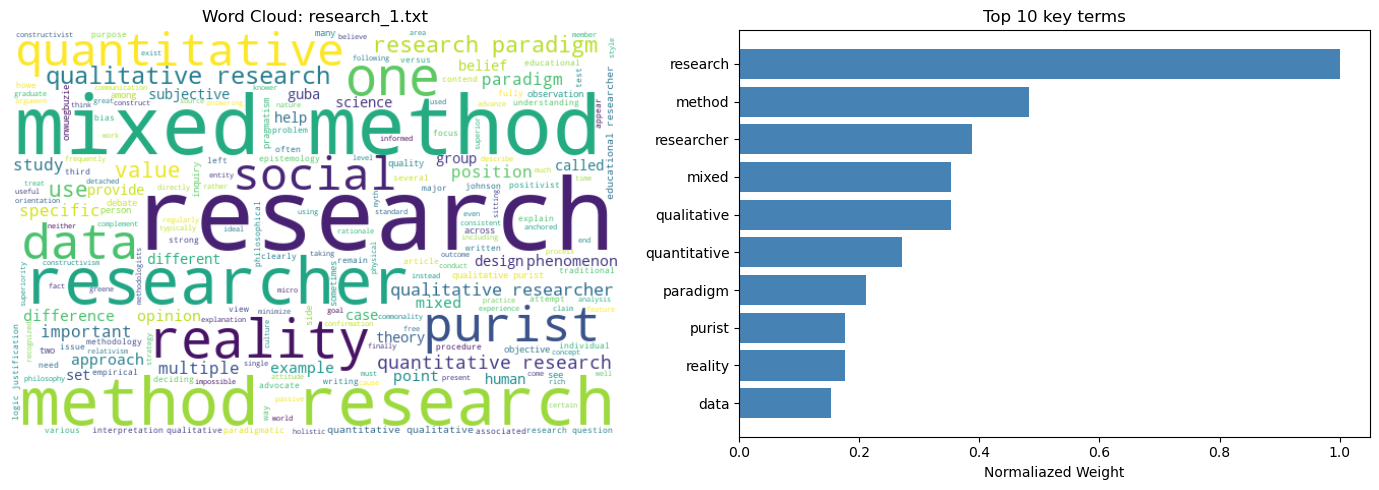

In [206]:
#clean import block
from collections import Counter
import heapq
from nltk.tokenize import sent_tokenize
from wordcloud import WordCloud

first_title = articles_df.loc[0, 'Articles_Title']
first_raw = articles_df.loc[0, 'Content']
first_clean = articles_df.loc[0, 'Clean_Content']

# freaquency based extractive summarisation
word_freq = Counter(first_clean.split())
max_freq = max(word_freq.values())

for word in word_freq:
  word_freq[word] = word_freq[word] / max_freq

sentences = sent_tokenize(first_raw)
sentence_score = {}

for sent in sentences:
    words_in_sent = word_tokenize(re.sub(r'[^a-zA-Z\s]', '', sent.lower()))
    if 8 <= len(words_in_sent) < 45:
      for word in words_in_sent:
        lemma = lemmatizer.lemmatize(word)
        if lemma in word_freq:
          sentence_score[sent] = (
              sentence_score.get(sent, 0) + word_freq[lemma]
          )
summary_sentences = heapq.nlargest(5, sentence_score, key=sentence_score.get)
first_article_summary = ' '.join(summary_sentences)

print({first_title})
print(first_article_summary)

    #word cloud and the top key terms bar chart
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

wc = WordCloud(
    width=600, height=400, background_color='white', colormap='viridis'
).generate(first_clean)
axes[0].imshow(wc, interpolation='bilinear')
axes[0].axis('off')
axes[0].set_title(f'Word Cloud: {first_title}')

top_words = word_freq.most_common(10)
words, freqs = zip(*top_words)
axes[1].barh(words[::-1], freqs[::-1], color='steelblue')
axes[1].set_title('Top 10 key terms')
axes[1].set_xlabel('Normaliazed Weight')

plt.tight_layout()
plt.show()

## Question 3.4
#### Aggregate summarisation of the remaining articles


In [163]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer

# exclude research_1 because its already summised above
remaining_articles = articles_df.iloc[1:].copy()

#combining the articles into one corpus
aggregate_raw_text = ' '.join(remaining_articles['Content'].astype(str))

print('Articles includes in the aggregate corpus:')
print(remaining_articles['Articles_Title'].tolist())
print('\nNumber of remaining articles:', len(remaining_articles))

#splitting the aggrate into sentences

aggregate_senteces = [
    sentence.strip()
    for sentence in sent_tokenize(aggregate_raw_text) 
    if 8 <= len(word_tokenize(sentence)) < 45
]

# convert sentencs into TF-IDF matrix
tfidf_vec = TfidfVectorizer(
    stop_words='english',
    lowercase=True
)

tfidf_matrix = tfidf_vec.fit_transform(aggregate_senteces)

#selecting top 10 scoring sentences

sentence_score = np.asarray(
    tfidf_matrix.mean(axis=1)
).ravel()

number_of_sentences = min(10, len(aggregate_senteces))
top_sentence_indices = sentence_score.argsort()[-number_of_sentences:]

#restore the selected to their origninal document
top_sentence_indices = sorted(top_sentence_indices)

aggregate_summary = ' '.join(
    aggregate_senteces[index]
    for index in top_sentence_indices
)

print('nAggregate Summary of the remaining Articles')


Articles includes in the aggregate corpus:
['research_2.txt', 'research_3.txt', 'research_4.txt', 'research_5.txt']

Number of remaining articles: 4
nAggregate Summary of the remaining Articles


#### Visualisation of aggregate TF-IDF scores

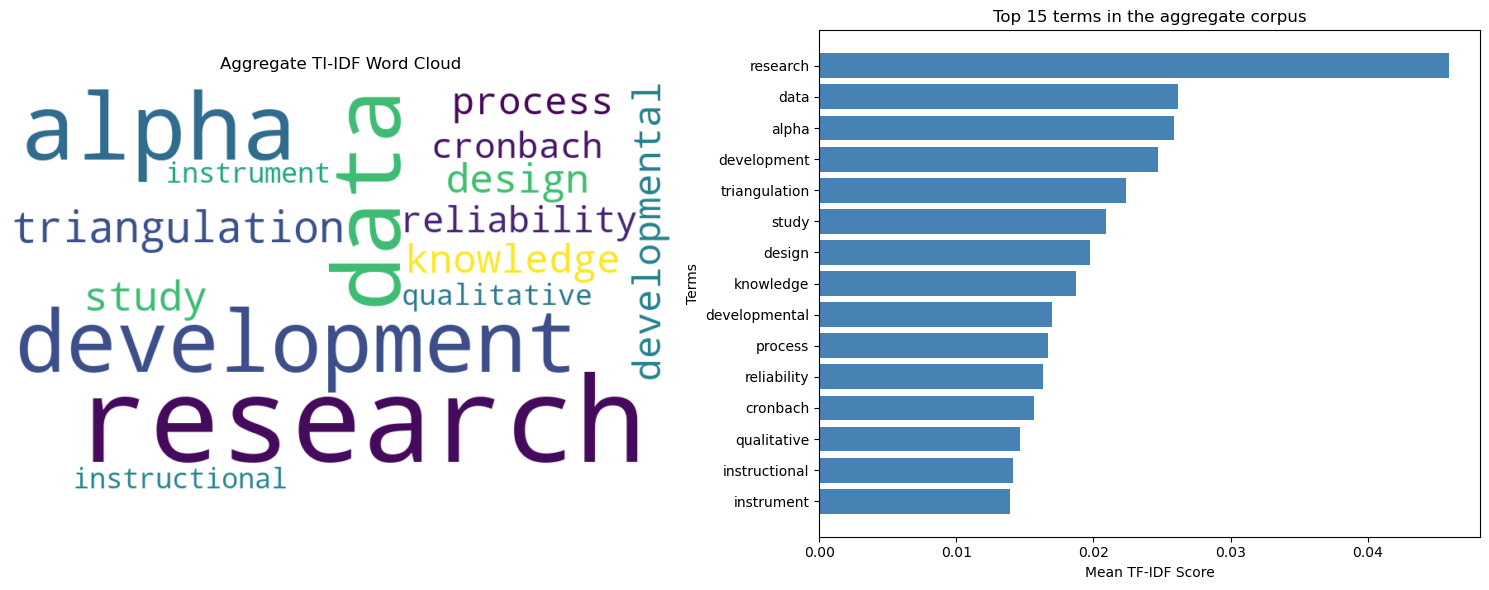

In [164]:
#get the important terms and the TF-IDF scores
feature_names = np.array(tfidf_vec.get_feature_names_out())
term_scores = np.asarray(tfidf_matrix.mean(axis=0)).ravel()

#top 15 terms
top_terms_indices = term_scores.argsort()[-15:][::-1]

top_terms = feature_names[top_terms_indices]
top_scores = term_scores[top_terms_indices]

#creating word frequencies for the word cloud
wordcloud_freq = dict(zip(top_terms, top_scores))

#creating visuals
    
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

aggregate_wordcloud = WordCloud(
    width=800, height=500, background_color='white', colormap='viridis'
).generate_from_frequencies(wordcloud_freq)

axes[0].imshow(aggregate_wordcloud, interpolation='bilinear')
axes[0].axis('off')
axes[0].set_title(f'Aggregate TI-IDF Word Cloud')

axes[1].barh(top_terms[::-1], top_scores[::-1], color='steelblue')
axes[1].set_title('Top 15 terms in the aggregate corpus')
axes[1].set_xlabel('Mean TF-IDF Score')
axes[1].set_ylabel('Terms')

plt.tight_layout()
plt.show()

The TF-IDF summarisation was applied to the four remaining researc articles as a combined corpus. The word cloud and bar chart highlight important terms in the articles, Research has the highest mean TD-IDF score followed by data, alphe, development and triangulation. The visuals help idemtify the main concepts represented in the combined corpus.

## Question 4
#### Topic modelling using LDA

In [179]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
import seaborn as sns

#creating document term matric for cleaned articles
count_vectorizer = CountVectorizer(
    max_df=0.95,
    min_df=1,
    max_features=1000
    )

document_term_matrix = count_vectorizer.fit_transform(
    articles_df['Clean_Content'].fillna('')
)

print('Document-Term Matrix', document_term_matrix.shape)

Document-Term Matrix (5, 1000)


In [180]:
#build the LDA
number_of_topics = 3

lda_model = LatentDirichletAllocation(
    n_components=number_of_topics,
    random_state=42,
    learning_method='batch'
)

#train the model using the document term matrix
document_topic_distribution = lda_model.fit_transform(
    document_term_matrix
)

print('LDA model - number of topics', number_of_topics)

LDA model - number of topics 3


In [181]:
#display the top 10 words for eah LDA topic
feature_names = count_vectorizer.get_feature_names_out()

number_of_words = 10

for topic_number, topic_weights in enumerate(lda_model.components_):
    top_terms_indices = topic_weights.argsort()[-number_of_words:][::-1]

    top_words = feature_names[top_terms_indices]

    print({topic_number +1})
    print(', '.join(top_words))

{1}
alpha, development, cronbach, instrument, science, reliability, scale, developmental, design, item
{2}
method, mixed, quantitative, paradigm, reflexivity, reality, purist, position, many, educational
{3}
triangulation, method, design, denzin, fusch, multiple, source, mixed, change, bias


,Article,Topic 1,Topic 2,Topic 3
0,research_1.txt,0.000178,0.999645,0.000178
1,research_2.txt,0.000627,0.998738,0.000635
2,research_3.txt,0.999419,0.000303,0.000278
3,research_4.txt,0.999690,0.000155,0.000155
4,research_5.txt,0.000264,0.000270,0.999466


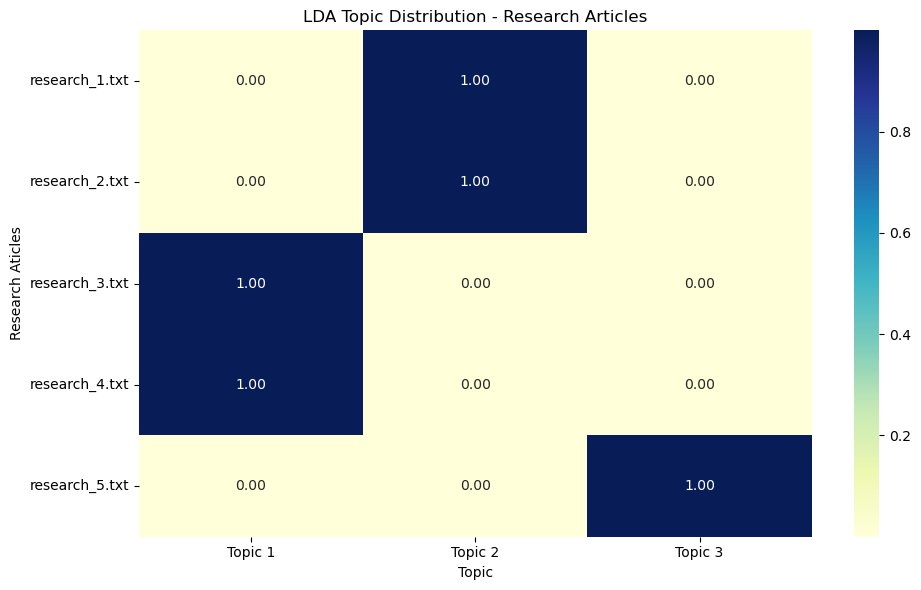

In [182]:
#topic distribution accross the five 5 articles

topic_distribution_df = pd.DataFrame(
    document_topic_distribution,
    columns=['Topic 1','Topic 2', 'Topic 3']
)

topic_distribution_df.insert(
    0,
    'Article',
    articles_df['Articles_Title'].values
)

#displaying the distribution table
display(topic_distribution_df)
plt.figure(figsize=(10, 6))
sns.heatmap(
    topic_distribution_df.set_index('Article'),
    annot=True,
    cmap='YlGnBu',
    fmt='.2f'
)

plt.title('LDA Topic Distribution - Research Articles')
plt.xlabel('Topic')
plt.ylabel('Research Aticles')

plt.tight_layout()
plt.show()


The LDA model identified three main topic sccross the five research artiles. Topic 1 focuses on research instrument development and reliability and is dominant in research_3 and research4 text files. Topic 2 represents mized methods reearch and is dominant in research_1 and research 2 text files. Topic 3 relates to research trianglulation and is dominant in research_5. The heatmap shows that each article is strongly assocciated with one main topic.

## Question 4.2
#### Interactive intertopic distance map using pyLDAvis

In [184]:
import pyLDAvis
import pyLDAvis.lda_model

#generate the map
lda_visual = pyLDAvis.lda_model.prepare(
    lda_model,
    document_term_matrix,
    count_vectorizer
)

pyLDAvis.display(lda_visual)


In [186]:
#save the map
pyLDAvis.save_html(
    lda_visual,
    'LDA_Intertopic_Distance_Map.html'
)

The map visualses the 3 topics identifie using LDA. Topic circles indicates difference in thw word distribition. Circle size represnet their relative prevalancewithin the corpus. The most salient terms include mthod, alpha, triangulation, development and design. Visual allows users to explore individual topics.

## Question 4.3

##### GitHub repoository
https://github.com/eduv13142709/ITNPA4-34-NLP-Project.git

